# NYC Property Sales: Borough Classification Modeling

**Research question:** Using only a property's characteristics and its sale (price, size, units, age, building
type, tax class, and sale timing), can we predict which of the five boroughs the property is located in?

**Response variable:** `Borough_Name` (Bronx, Brooklyn, Manhattan, Queens, Staten Island), a 5-class
multiclass classification problem

**What this notebook does**

| Section | Contents |
|---|---|
| 1. Setup & data load | Load the cleaned parquet produced by `data_cleaning.ipynb` |
| 2. Preprocessing & feature engineering | Leakage removal, filtering, outlier treatment, missing values, bucketing high-cardinality categoricals, log transforms, engineered features |
| 3. Data splitting | Train / test split (test set held out until final evaluation), class proportions check, class weights computed on train only |
| 4. Model construction | Three `Pipeline` models, each tuned with **k-fold cross validation**: <br>• **Benchmark:** multinomial Logistic Regression on 4 features (scaled) <br>• **Random Forest** on all features <br>• **Gradient Boosted Trees** (one-vs-rest) on all features |
| 5. Model evaluation | Accuracy, precision, recall, F1, confusion matrices, AUROC (one-vs-rest, per class and macro) for every model; model comparison; champion selection |
| 6. Sensitivity analysis | Champion model's metrics across different hyperparameter values |

## 1. Setup & Data Load

In [1]:
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.ml import Pipeline
from pyspark.ml.feature import (StringIndexer, OneHotEncoder, VectorAssembler,
                                StandardScaler, Imputer)
from pyspark.ml.classification import (LogisticRegression, RandomForestClassifier,
                                       GBTClassifier, OneVsRest)
from pyspark.ml.evaluation import (MulticlassClassificationEvaluator,
                                   BinaryClassificationEvaluator)
from pyspark.ml.tuning import ParamGridBuilder, CrossValidator
from pyspark.ml.functions import vector_to_array

### Configuration
- `CV_SAMPLE_FRACTION`: cross validation fits every model `k × (grid size)` times. Hyperparameter search is run
  on a random sample of the training set. The best hyperparameters are then refit on the full training set.
- `QUICK_TEST`: set to `True` to run the whole notebook on a 5% sample with tiny hyperparameter grids. This checks
  that the pipeline works end to end in a few minutes before the full run as recommended in the project instructions.
- `DRIVER_MEMORY`: Spark driver memory
- `GRIDS`: hyperparameter values searched with k-fold cross validation

In [ ]:
DATA_PATH = os.path.expanduser("~/NYC_Property_Sales/data/nyc_property_sales_cleaned")
SEED               = 42
TEST_FRACTION      = 0.20     # held-out test set
K_FOLDS            = 3        # k-fold cross validation
CV_SAMPLE_FRACTION = 0.1     # fraction of the training set used for CV hyperparameter search
SENS_SAMPLE_FRACTION = 0.25   # fraction of the training set used for the sensitivity analysis
QUICK_TEST         = False    # set True to test the pipeline on a 5% sample with tiny grids
QUICK_TEST         = QUICK_TEST or os.environ.get("QUICK_TEST", "0") == "1"
DRIVER_MEMORY      = os.environ.get("SPARK_DRIVER_MEMORY", "16g")  

# Hyperparameter grids for k-fold CV (values swept in the sensitivity analysis are in Section 6)
GRIDS = {
    "lr_regParam":  [0.0, 0.01, 0.1],
    "rf_numTrees":  [50, 100],
    "rf_maxDepth":  [8, 12],
    "gbt_maxDepth": [3, 5],
    "gbt_maxIter":  [20],     # one-vs-rest GBT trains 5 boosted models per setting per fold, so keep this small
}
if QUICK_TEST:   # tiny grids: only checks that every cell runs
    K_FOLDS = 2
    GRIDS = {"lr_regParam": [0.0, 0.1], "rf_numTrees": [20], "rf_maxDepth": [5, 8],
             "gbt_maxDepth": [3], "gbt_maxIter": [5]}

spark = (SparkSession.builder
         .master("local[*]")
         .appName("borough_classification")
         .config("spark.driver.memory", DRIVER_MEMORY)
         .config("spark.sql.shuffle.partitions", "64")
         .getOrCreate())
spark.sparkContext.setLogLevel("ERROR")
spark.conf.set("spark.sql.execution.arrow.pyspark.enabled", "false")

df_raw = spark.read.parquet(DATA_PATH)
if QUICK_TEST:
    df_raw = df_raw.sample(fraction=0.05, seed=SEED)

print(f"Rows loaded: {df_raw.count():,}")
df_raw.printSchema()

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/testing/utils.py:127: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
26/11/05 15:32:23 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


Rows loaded: 1,600,162
root
 |-- Borough: integer (nullable = true)
 |-- Neighborhood: string (nullable = true)
 |-- Building Class Category: string (nullable = true)
 |-- Tax Class At Present: string (nullable = true)
 |-- Block: string (nullable = true)
 |-- Lot: string (nullable = true)
 |-- Building Class At Present: string (nullable = true)
 |-- Address: string (nullable = true)
 |-- Apartment Number: string (nullable = true)
 |-- Zip Code: integer (nullable = true)
 |-- Residential Units: integer (nullable = true)
 |-- Commercial Units: integer (nullable = true)
 |-- Total Units: integer (nullable = true)
 |-- Land Square Feet: double (nullable = true)
 |-- Gross Square Feet: double (nullable = true)
 |-- Year Built: integer (nullable = true)
 |-- Tax Class At Time Of Sale: string (nullable = true)
 |-- Building Class At Time Of Sale: string (nullable = true)
 |-- Sale Price: double (nullable = true)
 |-- Sale Date: date (nullable = true)
 |-- Year: integer (nullable = true)
 |--

## 2. Data Preprocessing & Feature Engineering

### 2.1 Removing target leakage

Several columns identify the borough directly or almost directly. Using them would make the problem trivial
(100% accuracy) and would not answer the research question, so they are excluded from the features:

| Column | Why it leaks |
|---|---|
| `Borough` | Numeric borough code (1–5), identical to the target |
| `Neighborhood` | Every neighborhood belongs to exactly one borough |
| `Zip Code` | Zip codes map almost one-to-one to boroughs |
| `Address`, `Apartment Number` | Street addresses identify location |
| `Block`, `Lot` | Tax-lot identifiers numbered within each borough |
| `Tax Class At Present`, `Building Class At Present` | Measured after the sale; duplicates the at-time-of-sale columns |

The check below confirms the leakage for `Neighborhood` and `Zip Code`

In [3]:
# How many boroughs does each neighborhood / zip code appear in?
for c in ["Neighborhood", "Zip Code"]:
    per_value = df_raw.groupBy(c).agg(F.countDistinct("Borough_Name").alias("n_boroughs"))
    share_unique = per_value.filter(F.col("n_boroughs") == 1).count() / per_value.count()
    print(f"{c:<13}: {share_unique:.1%} of values belong to a single borough")

Neighborhood : 99.3% of values belong to a single borough
Zip Code     : 97.5% of values belong to a single borough


### 2.2 Duplicates and non-market sales

- Exact duplicate rows are dropped
- About 30% of records have a $0 sale price (gifts, inheritances, deed transfers) and others have nominal prices
  ($1, $10, ...). These are not market transactions and carry no price information, so sales under $10,000 are
  removed.
- `Sale Date` and `Year Built` must be present to compute building age and sale timing; rows with impossible
  values are handled as missing in 2.4 rather than dropped.

In [4]:
TARGET = "Borough_Name"

n0 = df_raw.count()
df = df_raw.dropDuplicates()
n1 = df.count()
df = df.filter(F.col("Sale Price") >= 10000).filter(F.col(TARGET).isNotNull())
n2 = df.count()

print(f"Start:                       {n0:,}")
print(f"After dropping duplicates:   {n1:,}  (-{n0 - n1:,})")
print(f"After removing < $10k sales: {n2:,}  (-{n1 - n2:,})")

[Stage 45:====================================>                     (5 + 3) / 8]

Start:                       1,600,162
After dropping duplicates:   1,571,610  (-28,552)
After removing < $10k sales: 1,078,708  (-492,902)


### 2.3 Bucketing high-cardinality categoricals

- **`Building Class Category`** has ~99 distinct strings, but many are the same category written differently across
  years (e.x. `01  ONE FAMILY HOMES`, `01 ONE FAMILY DWELLINGS`). The leading 2-digit code is the true category, so
  it is extracted and used instead (about 45 levels).
- **`Building Class At Time Of Sale`** has ~215 codes (A1, A5, R4, ...). The first letter is the building type
  family (A = one-family, B = two-family, C = walk-up, D = elevator, R = condo, ...), which buckets it to ~26 levels.
- **`Tax Class At Time Of Sale`** has only 4 levels and is kept as is.

In [5]:
df = (df
      .withColumn("bldg_cat_code",
                  F.regexp_extract(F.col("Building Class Category"), r"^\s*(\d{2})", 1))
      .withColumn("bldg_cat_code",
                  F.when(F.col("bldg_cat_code") == "", None).otherwise(F.col("bldg_cat_code")))
      .withColumn("bldg_class_letter", F.upper(F.substring("Building Class At Time Of Sale", 1, 1)))
      .withColumn("tax_class_sale", F.col("Tax Class At Time Of Sale")))

for raw, new in [("Building Class Category", "bldg_cat_code"),
                 ("Building Class At Time Of Sale", "bldg_class_letter")]:
    print(f"{raw:<32} {df.select(raw).distinct().count():>4} levels  ->  "
          f"{new:<18} {df.select(new).distinct().count():>3} levels")

Building Class Category            99 levels  ->  bldg_cat_code       48 levels


[Stage 73:>                                                         (0 + 8) / 8]

Building Class At Time Of Sale    210 levels  ->  bldg_class_letter   25 levels


### 2.4 Missing values, outliers, and transformations

Missing / placeholder values: In the raw data, a value of `0` for square footage or year built means "not
recorded", not a real zero. This is common for co-op and condo units which are concentrated in Manhattan, so
dropping these rows would remove much of one borough and bias the data. Instead:

- `0` square feet and `Year Built` outside 1800–sale year are converted to `null`.
- A binary missing-indicator flag is added for each (`has_gross_sqft`, `has_land_sqft`, `has_year_built`).
  Missingness itself is informative (e.x. apartments vs. houses).
- Remaining nulls are filled with the training-set median using `Imputer` inside each pipeline, so no
  information from the test set is used.

Outliers: Sale price and square footage are extremely right skewed (prices up to $4B). Rather than dropping
large but legitimate sales, they are log-transformed which compresses extreme values. Unit counts are capped at
the 99.9th percentile of the data.

Engineered features:

| Feature | Definition |
|---|---|
| `log_sale_price` | log(Sale Price) |
| `log_gross_sqft`, `log_land_sqft` | log(1 + square feet) |
| `log_price_per_sqft` | log(Sale Price / Gross Square Feet), when sqft is known |
| `building_age` | Sale year − Year Built |
| `sale_year`, `sale_month` | Timing of the sale (market conditions and seasonality) |

In [ ]:
df = (df
      .withColumn("gross_sqft", F.when(F.col("Gross Square Feet") > 0, F.col("Gross Square Feet")))
      .withColumn("land_sqft",  F.when(F.col("Land Square Feet") > 0, F.col("Land Square Feet")))
      .withColumn("year_built", F.when((F.col("Year Built") >= 1800) &
                                       (F.col("Year Built") <= F.col("Year")), F.col("Year Built")))
      .withColumn("has_gross_sqft", F.col("gross_sqft").isNotNull().cast("double"))
      .withColumn("has_land_sqft",  F.col("land_sqft").isNotNull().cast("double"))
      .withColumn("has_year_built", F.col("year_built").isNotNull().cast("double"))
      .withColumn("log_sale_price", F.log(F.col("Sale Price")))
      .withColumn("log_gross_sqft", F.log1p("gross_sqft"))
      .withColumn("log_land_sqft",  F.log1p("land_sqft"))
      .withColumn("log_price_per_sqft", F.log(F.col("Sale Price") / F.col("gross_sqft")))
      .withColumn("building_age", (F.col("Year") - F.col("year_built")).cast("double"))
      .withColumn("sale_year",  F.col("Year").cast("double"))
      .withColumn("sale_month", F.month("Sale Date").cast("double")))

# Cap unit counts at the 99.9th percentile
unit_cols = ["Residential Units", "Commercial Units", "Total Units"]
caps = df.approxQuantile(unit_cols, [0.999], 0.0001)
for c, cap in zip(unit_cols, caps):
    new = c.lower().replace(" ", "_")
    df = df.withColumn(new, F.least(F.col(c), F.lit(cap[0])).cast("double"))
    print(f"{c:<18} capped at {cap[0]:,.0f}")

[Stage 81:===================================================>      (8 + 1) / 9]

Residential Units  capped at 133
Commercial Units   capped at 13
Total Units        capped at 145


In [7]:
CAT_FEATURES = ["bldg_cat_code", "bldg_class_letter", "tax_class_sale"]
NUM_FEATURES = ["log_sale_price", "log_gross_sqft", "log_land_sqft", "log_price_per_sqft",
                "residential_units", "commercial_units", "total_units",
                "building_age", "sale_year", "sale_month",
                "has_gross_sqft", "has_land_sqft", "has_year_built"]

model_df = df.select([TARGET] + CAT_FEATURES + NUM_FEATURES)

# Missing values per feature before imputation
missing = model_df.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in model_df.columns])
missing_pd = missing.toPandas().T.rename(columns={0: "nulls"})
missing_pd["share"] = (missing_pd["nulls"] / model_df.count()).map("{:.1%}".format)
missing_pd

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

,nulls,share
Borough_Name,0,0.0%
bldg_cat_code,252,0.0%
bldg_class_letter,0,0.0%
tax_class_sale,0,0.0%
log_sale_price,0,0.0%
log_gross_sqft,530053,49.1%
log_land_sqft,520980,48.3%
log_price_per_sqft,530053,49.1%
residential_units,0,0.0%
commercial_units,0,0.0%


Categorical nulls are handled by `StringIndexer(handleInvalid="keep")`, which gives missing and unseen levels their
own index. Numeric nulls are imputed with the training median inside each pipeline.

### 2.5 Target distribution

The classes are imbalanced: Staten Island and the Bronx have far fewer sales than Queens, Brooklyn and Manhattan.
This matters for evaluation (accuracy alone can be misleading) and is addressed with class weights in Section 3.

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

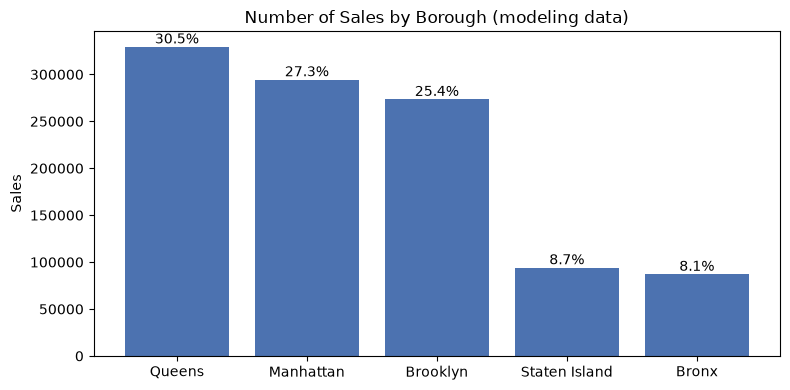

Majority-class baseline accuracy (always predict Queens): 0.3054


In [8]:
class_counts = model_df.groupBy(TARGET).count().orderBy(F.desc("count")).toPandas()
class_counts["share"] = class_counts["count"] / class_counts["count"].sum()

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(class_counts[TARGET], class_counts["count"], color="#4C72B0")
for i, (n, s) in enumerate(zip(class_counts["count"], class_counts["share"])):
    ax.text(i, n, f"{s:.1%}", ha="center", va="bottom")
ax.set_title("Number of Sales by Borough (modeling data)")
ax.set_ylabel("Sales")
ax.ticklabel_format(style="plain", axis="y")
plt.tight_layout()
plt.show()

MAJORITY_SHARE = class_counts["share"].max()
print(f"Majority-class baseline accuracy (always predict {class_counts[TARGET].iloc[0]}): "
      f"{MAJORITY_SHARE:.4f}")

How well do the features separate boroughs on their own? Sale price and building type differ strongly across
boroughs, which suggests the problem is learnable without location columns.

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
                                                                                

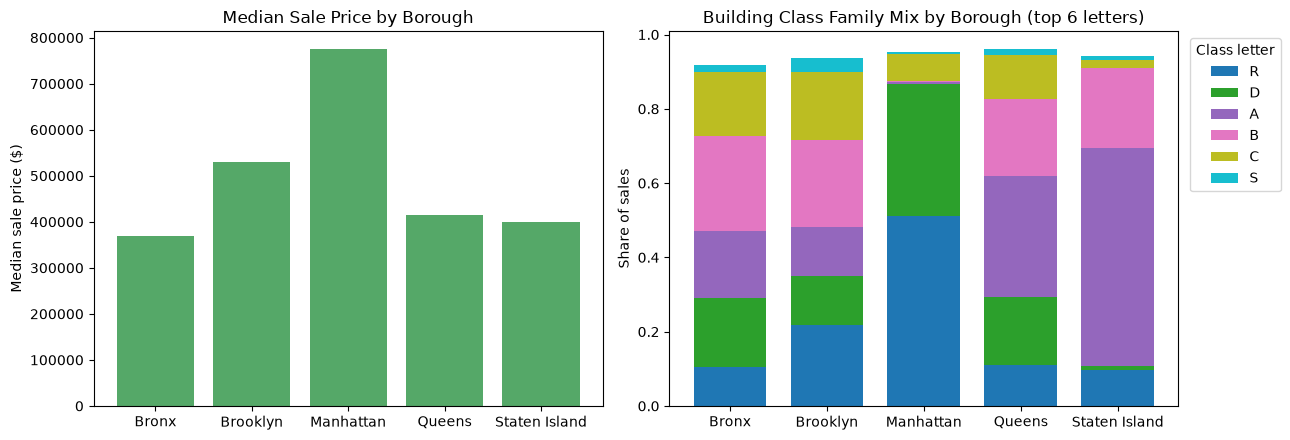

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Median log price by borough
med = (model_df.groupBy(TARGET)
       .agg(F.expr("percentile_approx(log_sale_price, 0.5)").alias("median_log_price"))
       .orderBy(TARGET).toPandas())
axes[0].bar(med[TARGET], np.exp(med["median_log_price"]), color="#55A868")
axes[0].set_title("Median Sale Price by Borough")
axes[0].set_ylabel("Median sale price ($)")
axes[0].ticklabel_format(style="plain", axis="y")

# Building type mix by borough
mix = (model_df.groupBy(TARGET, "bldg_class_letter").count().toPandas()
       .pivot(index=TARGET, columns="bldg_class_letter", values="count").fillna(0))
top_letters = mix.sum().sort_values(ascending=False).index[:6]
mix = mix[top_letters].div(mix.sum(axis=1), axis=0)
mix.plot(kind="bar", stacked=True, ax=axes[1], colormap="tab10", width=0.75)
axes[1].set_title("Building Class Family Mix by Borough (top 6 letters)")
axes[1].set_ylabel("Share of sales")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Class letter", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

## 3. Data Splitting

- The target is indexed to a numeric `label` once, so every model and confusion matrix uses the same class order.
- An 80/20 train/test split is made. The test set is set aside and not used in any training, tuning, or
  model selection. It is only used in Section 5 for final evaluation.
- Hyperparameters are chosen with k-fold cross validation on the training set (Section 4). The sensitivity
  analysis (Section 6) uses a separate train/validation split carved out of the training set.

In [10]:
label_indexer = StringIndexer(inputCol=TARGET, outputCol="label",
                              stringOrderType="alphabetAsc").fit(model_df)
LABELS = label_indexer.labels
print("Label mapping:", dict(enumerate(LABELS)))

indexed = label_indexer.transform(model_df)
train, test = indexed.randomSplit([1 - TEST_FRACTION, TEST_FRACTION], seed=SEED)
train, test = train.cache(), test.cache()

n_train, n_test = train.count(), test.count()
print(f"Train rows: {n_train:,}   Test rows: {n_test:,}")

# Check that class proportions are similar in train and test
props = (train.groupBy(TARGET).count().withColumnRenamed("count", "train")
         .join(test.groupBy(TARGET).count().withColumnRenamed("count", "test"), TARGET)
         .toPandas().set_index(TARGET).sort_index())
props["train_share"] = (props["train"] / props["train"].sum()).map("{:.2%}".format)
props["test_share"]  = (props["test"]  / props["test"].sum()).map("{:.2%}".format)
props

Label mapping: {0: 'Bronx', 1: 'Brooklyn', 2: 'Manhattan', 3: 'Queens', 4: 'Staten Island'}


Train rows: 862,432   Test rows: 216,276


/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


,train,test,train_share,test_share
Borough_Name,,,,
Bronx,69780,17397,8.09%,8.04%
Brooklyn,218740,54783,25.36%,25.33%
Manhattan,235536,58933,27.31%,27.25%
Queens,263349,66068,30.54%,30.55%
Staten Island,75027,19095,8.70%,8.83%


### Class weights (training set only)

To keep the models from favoring the large boroughs, each training row gets a weight inversely proportional to its
class frequency: `weight = n_train / (n_classes × n_class)`. The weights are computed **from the training set only**
and the test set keeps its natural class distribution, as recommended for imbalanced labels.

In [11]:
class_n = {r["label"]: r["count"] for r in train.groupBy("label").count().collect()}
weights = {k: n_train / (len(class_n) * v) for k, v in class_n.items()}
for k in sorted(weights):
    print(f"{LABELS[int(k)]:<14} weight = {weights[k]:.3f}")

weight_expr = F.create_map([F.lit(x) for kv in weights.items() for x in kv])
train = train.withColumn("class_weight", weight_expr[F.col("label")]).cache()

# Sample of the training set used for k-fold CV hyperparameter search
cv_train = train.sample(fraction=CV_SAMPLE_FRACTION, seed=SEED).cache()
print(f"\nCV tuning sample: {cv_train.count():,} rows")

Bronx          weight = 2.472
Brooklyn       weight = 0.789
Manhattan      weight = 0.732
Queens         weight = 0.655
Staten Island  weight = 2.299

CV tuning sample: 86,668 rows


## 4. Model Construction

Every model is a single `Pipeline`, so all preprocessing (indexing, encoding, imputing, scaling) is fit only on the
data the pipeline is trained on. This keeps each cross-validation fold and the test set free of leakage.

Shared preprocessing stages:
- `StringIndexer` for the categorical features (`handleInvalid="keep"` puts nulls and unseen levels in their own bucket)
- `Imputer` (median) for numeric nulls

Model-specific stages:
- Logistic Regression needs dummy variables (`OneHotEncoder`) and feature scaling (`StandardScaler`)
  because it is sensitive to feature scale and treats indexed categories as ordered numbers otherwise.
- Tree models split on thresholds, so they use the indexed categories directly and do not need scaling.

Hyperparameters for each model are tuned with k-fold cross validation (`K_FOLDS = 3`), optimizing weighted F1 (better than
accuracy with imbalanced classes). The best setting is then refit on the full training set.

In [12]:
f1_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="f1")

def make_indexers(cols):
    return [StringIndexer(inputCol=c, outputCol=f"{c}_idx", handleInvalid="keep") for c in cols]

def make_imputer(cols):
    return Imputer(inputCols=cols, outputCols=[f"{c}_imp" for c in cols], strategy="median")

def tune_and_fit(name, pipeline, grid):
    """k-fold CV on the CV sample, then refit the best params on the full training set."""
    t0 = time.time()
    cv = CrossValidator(estimator=pipeline, estimatorParamMaps=grid, evaluator=f1_eval,
                        numFolds=K_FOLDS, seed=SEED, parallelism=1)
    cv_model = cv.fit(cv_train)

    # CV results table
    rows = []
    for pm, m in zip(grid, cv_model.avgMetrics):
        rows.append({**{p.name: v for p, v in pm.items()}, "cv_weighted_f1": m})
    cv_table = pd.DataFrame(rows).sort_values("cv_weighted_f1", ascending=False).reset_index(drop=True)

    best_params = grid[int(np.argmax(cv_model.avgMetrics))]
    final_model = pipeline.copy(best_params).fit(train)
    print(f"{name}: tuned + refit in {(time.time() - t0) / 60:.1f} min")
    print("Best params:", {p.name: v for p, v in best_params.items()})
    return final_model, cv_table, max(cv_model.avgMetrics)

results = {}   # name -> dict(model=..., cv_table=..., cv_f1=...)

### 4.1 Benchmark: Multinomial Logistic Regression (4 features)

A simple model with a small number of features provides the basis for comparison and a sanity check. It uses
`log_sale_price`, `log_gross_sqft`, `has_gross_sqft`, and `building_age`, scaled with `StandardScaler`. The
regularization strength `regParam` is tuned with CV.

In [13]:
BENCH_FEATURES = ["log_sale_price", "log_gross_sqft", "has_gross_sqft", "building_age"]

bench_imputer   = make_imputer(BENCH_FEATURES)
bench_assembler = VectorAssembler(inputCols=[f"{c}_imp" for c in BENCH_FEATURES], outputCol="raw_features")
bench_scaler    = StandardScaler(inputCol="raw_features", outputCol="features", withMean=True, withStd=True)
lr = LogisticRegression(featuresCol="features", labelCol="label", weightCol="class_weight",
                        family="multinomial", maxIter=100, elasticNetParam=0.0)

bench_pipeline = Pipeline(stages=[bench_imputer, bench_assembler, bench_scaler, lr])
bench_grid = ParamGridBuilder().addGrid(lr.regParam, GRIDS["lr_regParam"]).build()

bench_model, bench_cv, bench_cv_f1 = tune_and_fit("Benchmark LR", bench_pipeline, bench_grid)
results["Benchmark LR"] = dict(model=bench_model, cv_table=bench_cv, cv_f1=bench_cv_f1)
bench_cv

Benchmark LR: tuned + refit in 0.6 min
Best params: {'regParam': 0.0}


,regParam,cv_weighted_f1
0,0.00,0.409217
1,0.01,0.403382
2,0.10,0.387461


### 4.2 Random Forest (all features)

Random forest averages many decorrelated decision trees, capturing non-linear relationships and interactions
(e.x. price per square foot differs by building type). `numTrees` and `maxDepth` are tuned with CV.
`maxBins` is set above the number of building-category levels so every category can be split on.

In [14]:
TREE_FEATURES = [f"{c}_idx" for c in CAT_FEATURES] + [f"{c}_imp" for c in NUM_FEATURES]

tree_assembler = VectorAssembler(inputCols=TREE_FEATURES, outputCol="features")

rf = RandomForestClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                            maxBins=64, subsamplingRate=0.8, featureSubsetStrategy="sqrt", seed=SEED)

rf_pipeline = Pipeline(stages=make_indexers(CAT_FEATURES) + [make_imputer(NUM_FEATURES), tree_assembler, rf])
rf_grid = (ParamGridBuilder()
           .addGrid(rf.numTrees, GRIDS["rf_numTrees"])
           .addGrid(rf.maxDepth, GRIDS["rf_maxDepth"])
           .build())

rf_model, rf_cv, rf_cv_f1 = tune_and_fit("Random Forest", rf_pipeline, rf_grid)
results["Random Forest"] = dict(model=rf_model, cv_table=rf_cv, cv_f1=rf_cv_f1)
rf_cv

Random Forest: tuned + refit in 8.0 min
Best params: {'numTrees': 50, 'maxDepth': 12}


,numTrees,maxDepth,cv_weighted_f1
0,50,12,0.647190
1,100,12,0.647086
2,100,8,0.606150
3,50,8,0.603253


### 4.3 Gradient Boosted Trees (one-vs-rest, all features)

Spark's `GBTClassifier` only supports binary labels, so it is wrapped in `OneVsRest`, which trains one boosted
model per borough ("this borough vs. all others") and predicts the borough with the highest score. Boosting
builds trees sequentially, each one correcting the errors of the previous ones. `maxDepth` and `maxIter`
(number of boosting rounds) are tuned with CV. Because each setting trains five boosted models per fold, the CV
grid is kept small; a wider range of depths and rounds is explored in the sensitivity analysis if GBT is champion.
A slightly larger learning rate (`stepSize=0.2`) compensates for the small number of rounds.

In [15]:
gbt = GBTClassifier(featuresCol="features", labelCol="label", weightCol="class_weight",
                    maxBins=64, stepSize=0.2, subsamplingRate=0.8, seed=SEED)
ovr_gbt = OneVsRest(classifier=gbt, featuresCol="features", labelCol="label",
                    weightCol="class_weight", parallelism=5)

gbt_pipeline = Pipeline(stages=make_indexers(CAT_FEATURES) + [make_imputer(NUM_FEATURES), tree_assembler, ovr_gbt])
gbt_grid = (ParamGridBuilder()
            .addGrid(gbt.maxDepth, GRIDS["gbt_maxDepth"])
            .addGrid(gbt.maxIter, GRIDS["gbt_maxIter"])
            .build())

gbt_model, gbt_cv, gbt_cv_f1 = tune_and_fit("Gradient Boosted Trees", gbt_pipeline, gbt_grid)
results["Gradient Boosted Trees"] = dict(model=gbt_model, cv_table=gbt_cv, cv_f1=gbt_cv_f1)
gbt_cv

26/11/05 15:42:42 ERROR Utils: Uncaught exception in thread executor-heartbeater
java.lang.NullPointerException: Cannot invoke "java.util.concurrent.ConcurrentHashMap.isEmpty()" because the return value of "org.apache.spark.sql.util.PartitionKeyedAccumulator.byPartition()" is null
	at org.apache.spark.sql.util.PartitionKeyedAccumulator.isZero(PartitionKeyedAccumulator.scala:51)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2(Executor.scala:1536)
	at org.apache.spark.executor.Executor.$anonfun$reportHeartBeat$2$adapted(Executor.scala:1536)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:166)
	at scala.collection.immutable.Vector.filterImpl(Vector.scala:116)
	at scala.collection.StrictOptimizedIterableOps.filterNot(StrictOptimizedIterableOps.scala:220)
	at scala.collection.StrictOptimizedIterableOps.filterNot$(StrictOptimizedIterableOps.scala:220)
	at scala.collection.immutable.Vector.filterNot(Vector.scala:116)
	at org.apache.spark.executor.Executor.$anon

Gradient Boosted Trees: tuned + refit in 8.0 min
Best params: {'maxDepth': 5, 'maxIter': 20}


,maxDepth,maxIter,cv_weighted_f1
0,5,20,0.636963
1,3,20,0.599651


## 5. Model Evaluation (held-out test set)

Each model is evaluated on the test set, which was not used for training or tuning. Metrics:

- Accuracy: share of sales assigned to the correct borough
- Weighted precision, recall, F1: per-class metrics averaged by class size; per-class values are also shown
- Confusion matrix: which boroughs get confused with which
- AUROC: for a multiclass problem, computed one-vs-rest for each borough (this borough vs. all others) using
  the model's score for that borough, plus the macro average across the five boroughs

In [16]:
def evaluate(name, model, data):
    preds = model.transform(data).cache()

    out = {"model": name}
    for metric, key in [("accuracy", "accuracy"), ("weightedPrecision", "precision"),
                        ("weightedRecall", "recall"), ("f1", "f1")]:
        out[key] = MulticlassClassificationEvaluator(
            labelCol="label", predictionCol="prediction", metricName=metric).evaluate(preds)

    # Per-class precision / recall / F1 and confusion matrix from a single aggregation
    cm = (preds.groupBy("label", "prediction").count().toPandas()
          .pivot(index="label", columns="prediction", values="count")
          .reindex(index=range(len(LABELS)), columns=range(len(LABELS))).fillna(0))
    cm = cm.astype(int).values
    tp = np.diag(cm)
    prec = np.divide(tp, cm.sum(axis=0), out=np.zeros(len(LABELS)), where=cm.sum(axis=0) > 0)
    rec  = np.divide(tp, cm.sum(axis=1), out=np.zeros(len(LABELS)), where=cm.sum(axis=1) > 0)
    f1   = np.divide(2 * prec * rec, prec + rec, out=np.zeros(len(LABELS)), where=(prec + rec) > 0)

    # One-vs-rest AUROC using the model's per-class score
    score_col = "probability" if "probability" in preds.columns else "rawPrediction"
    scored = preds.select("label", vector_to_array(score_col).alias("scores")).cache()
    aucs = []
    for k in range(len(LABELS)):
        binary = scored.select((F.col("label") == k).cast("double").alias("y"),
                               F.col("scores")[k].alias("score"))
        aucs.append(BinaryClassificationEvaluator(labelCol="y", rawPredictionCol="score",
                                                  metricName="areaUnderROC").evaluate(binary))
    out["auroc_macro"] = float(np.mean(aucs))
    scored.unpersist()
    preds.unpersist()

    per_class = pd.DataFrame({"borough": LABELS, "precision": prec, "recall": rec, "f1": f1,
                              "auroc": aucs, "support": cm.sum(axis=1)})
    return out, per_class, cm

def plot_confusion(cm, title, ax):
    row_share = cm / cm.sum(axis=1, keepdims=True).clip(min=1)
    im = ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
    ax.set_xticks(range(len(LABELS)))
    ax.set_xticklabels(LABELS, rotation=35, ha="right")
    ax.set_yticks(range(len(LABELS)))
    ax.set_yticklabels(LABELS)
    ax.set_xlabel("Predicted borough")
    ax.set_ylabel("Actual borough")
    ax.set_title(title)
    for i in range(len(LABELS)):
        for j in range(len(LABELS)):
            ax.text(j, i, f"{row_share[i, j]:.2f}\n({cm[i, j]:,})", ha="center", va="center",
                    fontsize=8, color="white" if row_share[i, j] > 0.5 else "black")
    return im

test_metrics, per_class_tables, confusion = [], {}, {}
for name, r in results.items():
    m, pc, cm = evaluate(name, r["model"], test)
    m["cv_weighted_f1"] = r["cv_f1"]
    test_metrics.append(m)
    per_class_tables[name], confusion[name] = pc, cm

/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()
/apps/software/standard/core/pyspark/4.2.0-py3.14/lib/python3.14/site-packages/pyspark/sql/pandas/conversion.py:298: FutureWarning: PySpark does not yet fully support pandas >= 3.0.0. Some features may not work correctly. It is recommended to use pandas < 3.0.0 for now.
  require_minimum_pandas_version()


### 5.1 Benchmark: Logistic Regression

,model,accuracy,precision,recall,f1,auroc_macro,cv_weighted_f1
0,Benchmark LR,0.4364,0.4962,0.4364,0.4063,0.7639,0.4092


,borough,precision,recall,f1,auroc,support
0,Bronx,0.1828,0.3586,0.2422,0.7045,17397
1,Brooklyn,0.5147,0.2238,0.3119,0.6506,54783
2,Manhattan,0.5182,0.8400,0.6410,0.8857,58933
3,Queens,0.5964,0.2130,0.3139,0.7322,66068
4,Staten Island,0.3141,0.6451,0.4225,0.8464,19095


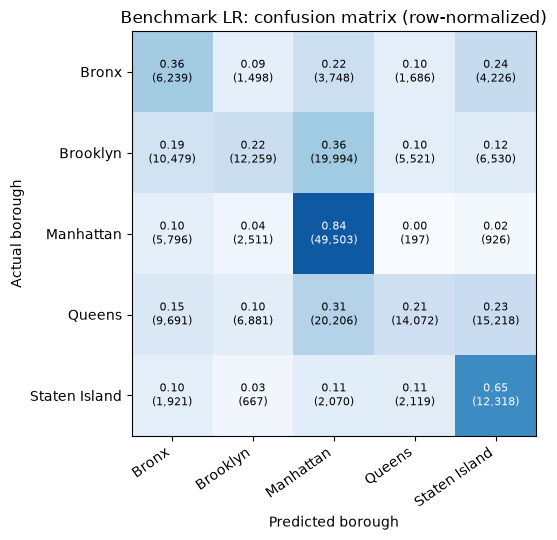

In [17]:
name = "Benchmark LR"
display(pd.DataFrame([m for m in test_metrics if m["model"] == name]).round(4))
display(per_class_tables[name].round(4))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_confusion(confusion[name], f"{name}: confusion matrix (row-normalized)", ax)
plt.tight_layout(); plt.show()

### 5.2 Random Forest

,model,accuracy,precision,recall,f1,auroc_macro,cv_weighted_f1
0,Random Forest,0.6468,0.6705,0.6468,0.6443,0.8969,0.6472


,borough,precision,recall,f1,auroc,support
0,Bronx,0.3242,0.6040,0.4219,0.8713,17397
1,Brooklyn,0.6501,0.4628,0.5407,0.8252,54783
2,Manhattan,0.7864,0.9068,0.8423,0.9682,58933
3,Queens,0.7023,0.5268,0.6020,0.8573,66068
4,Staten Island,0.5768,0.8264,0.6794,0.9624,19095


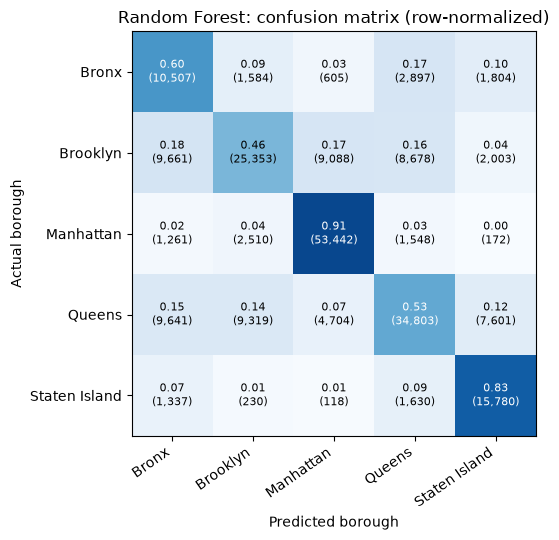

In [18]:
name = "Random Forest"
display(pd.DataFrame([m for m in test_metrics if m["model"] == name]).round(4))
display(per_class_tables[name].round(4))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_confusion(confusion[name], f"{name}: confusion matrix (row-normalized)", ax)
plt.tight_layout(); plt.show()

### 5.3 Gradient Boosted Trees

,model,accuracy,precision,recall,f1,auroc_macro,cv_weighted_f1
0,Gradient Boosted Trees,0.6413,0.6649,0.6413,0.6396,0.8889,0.637


,borough,precision,recall,f1,auroc,support
0,Bronx,0.3164,0.5923,0.4124,0.8626,17397
1,Brooklyn,0.6392,0.4664,0.5393,0.8127,54783
2,Manhattan,0.7915,0.9007,0.8426,0.9682,58933
3,Queens,0.6925,0.5173,0.5922,0.8406,66068
4,Staten Island,0.5704,0.8161,0.6715,0.9604,19095


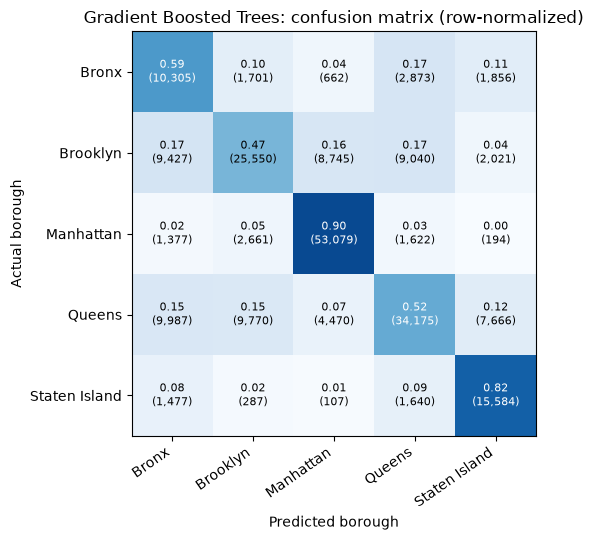

In [19]:
name = "Gradient Boosted Trees"
display(pd.DataFrame([m for m in test_metrics if m["model"] == name]).round(4))
display(per_class_tables[name].round(4))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
plot_confusion(confusion[name], f"{name}: confusion matrix (row-normalized)", ax)
plt.tight_layout(); plt.show()

### 5.4 Model comparison and champion selection

The champion is chosen by cross-validated weighted F1 on the training data, not by test performance, so
the test set remains an unbiased estimate of how the champion performs on new data. The majority-class baseline
accuracy is shown for reference.

In [20]:
comparison = (pd.DataFrame(test_metrics)
              [["model", "cv_weighted_f1", "accuracy", "precision", "recall", "f1", "auroc_macro"]]
              .rename(columns={"cv_weighted_f1": "CV weighted F1 (train)",
                               "accuracy": "Test accuracy", "precision": "Test weighted precision",
                               "recall": "Test weighted recall", "f1": "Test weighted F1",
                               "auroc_macro": "Test macro AUROC"}))
CHAMPION = comparison.loc[comparison["CV weighted F1 (train)"].idxmax(), "model"]
print(f"Majority-class baseline accuracy: {MAJORITY_SHARE:.4f}")
print(f"Champion model (highest CV weighted F1): {CHAMPION}")
comparison.round(4)

Majority-class baseline accuracy: 0.3054
Champion model (highest CV weighted F1): Random Forest


,model,CV weighted F1 (train),Test accuracy,Test weighted precision,Test weighted recall,Test weighted F1,Test macro AUROC
0,Benchmark LR,0.4092,0.4364,0.4962,0.4364,0.4063,0.7639
1,Random Forest,0.6472,0.6468,0.6705,0.6468,0.6443,0.8969
2,Gradient Boosted Trees,0.6370,0.6413,0.6649,0.6413,0.6396,0.8889


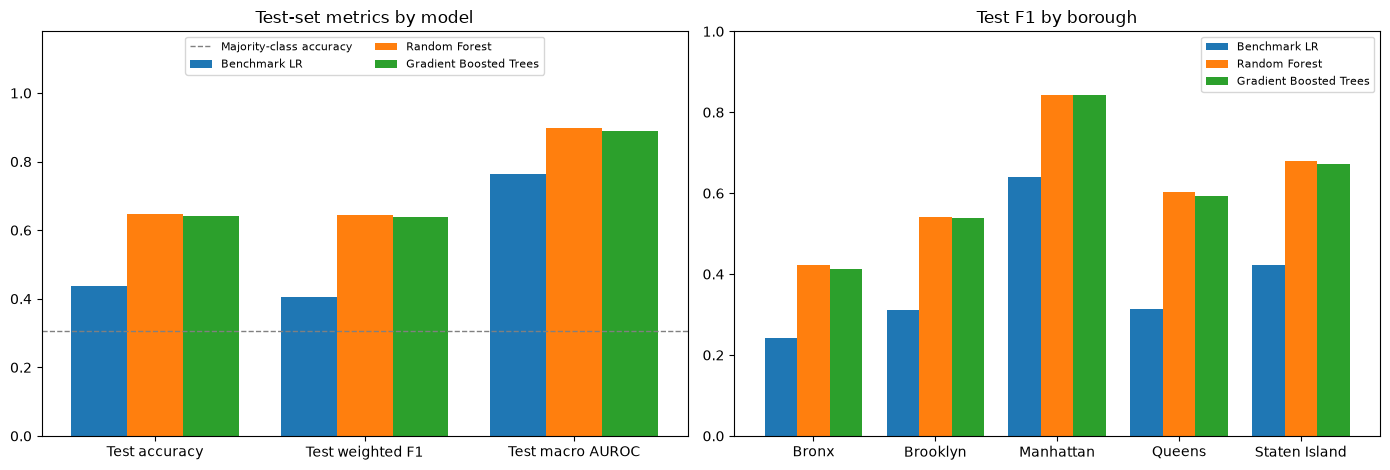

In [21]:
metric_cols = ["Test accuracy", "Test weighted F1", "Test macro AUROC"]
x = np.arange(len(metric_cols))
width = 0.8 / len(comparison)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for i, (_, row) in enumerate(comparison.iterrows()):
    axes[0].bar(x + i * width, row[metric_cols].astype(float), width, label=row["model"])
axes[0].axhline(MAJORITY_SHARE, color="gray", ls="--", lw=1, label="Majority-class accuracy")
axes[0].set_xticks(x + width * (len(comparison) - 1) / 2)
axes[0].set_xticklabels(metric_cols)
axes[0].set_ylim(0, 1.18)
axes[0].set_title("Test-set metrics by model")
axes[0].legend(loc="upper center", ncol=2, fontsize=8)

f1_by_class = pd.DataFrame({n: t.set_index("borough")["f1"] for n, t in per_class_tables.items()})
f1_by_class.plot(kind="bar", ax=axes[1], width=0.8)
axes[1].set_ylim(0, 1)
axes[1].set_title("Test F1 by borough")
axes[1].set_xlabel("")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

### 5.5 Feature importance (tree models)

Which property characteristics carry the most information about the borough? Importances are taken from the
fitted tree models (for one-vs-rest GBT, averaged across the five per-borough models).

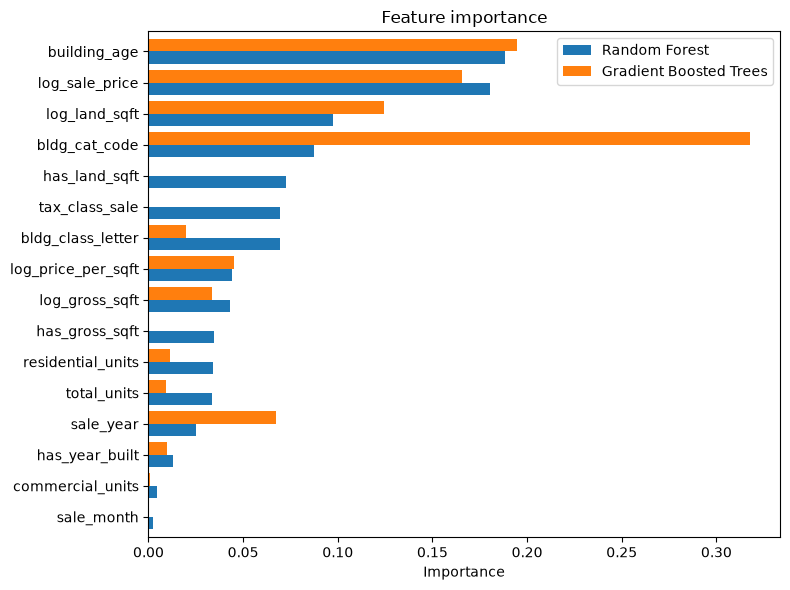

In [22]:
def importances(pipeline_model):
    clf = pipeline_model.stages[-1]
    if hasattr(clf, "featureImportances"):
        return clf.featureImportances.toArray()
    return np.mean([m.featureImportances.toArray() for m in clf.models], axis=0)   # OneVsRest

imp = pd.DataFrame({n: importances(results[n]["model"])
                    for n in ["Random Forest", "Gradient Boosted Trees"]},
                   index=[c.replace("_idx", "").replace("_imp", "") for c in TREE_FEATURES])
imp = imp.sort_values("Random Forest")

imp.plot(kind="barh", figsize=(8, 6), width=0.8)
plt.title("Feature importance")
plt.xlabel("Importance")
plt.tight_layout()
plt.show()

## 6. Sensitivity Analysis (champion model)

To see how sensitive the champion is to its hyperparameters, one hyperparameter is varied at a time while the
others are held at their tuned values. Each setting is trained on a sample of the training set and scored on a
validation split carved out of the training set, so the test set is still not used for any tuning decision.

In [23]:
sens_data = train.sample(fraction=SENS_SAMPLE_FRACTION, seed=SEED + 1)
sens_train, sens_valid = sens_data.randomSplit([0.8, 0.2], seed=SEED)
sens_train, sens_valid = sens_train.cache(), sens_valid.cache()
print(f"Sensitivity train: {sens_train.count():,}   validation: {sens_valid.count():,}")

champ_pipeline = {"Benchmark LR": bench_pipeline, "Random Forest": rf_pipeline,
                  "Gradient Boosted Trees": gbt_pipeline}[CHAMPION]

# Hyperparameter sweeps for each possible champion
SWEEPS = {
    "Benchmark LR":           {lr.regParam:  [0.0, 0.001, 0.01, 0.1, 0.5]},
    "Random Forest":          {rf.maxDepth:  [4, 8, 12, 16],
                               rf.numTrees:  [10, 25, 50, 100]},
    "Gradient Boosted Trees": {gbt.maxDepth: [2, 3, 5, 7],
                               gbt.maxIter:  [10, 20, 30, 40]},
}

if QUICK_TEST:
    SWEEPS = {k: {p: v[:2] for p, v in sw.items()} for k, sw in SWEEPS.items()}
    SWEEPS["Gradient Boosted Trees"] = {gbt.maxDepth: [2, 3], gbt.maxIter: [3, 5]}

def tuned_value(param):
    """Tuned value of a hyperparameter in the refit champion."""
    clf = results[CHAMPION]["model"].stages[-1]
    if CHAMPION == "Gradient Boosted Trees":
        clf = clf.models[0]
    return clf.getOrDefault(clf.getParam(param.name))

tuned = {p: tuned_value(p) for p in SWEEPS[CHAMPION]}
print("Tuned values held fixed:", {p.name: v for p, v in tuned.items()})

acc_eval = MulticlassClassificationEvaluator(labelCol="label", predictionCol="prediction", metricName="accuracy")
sens_rows = []
for param, values in SWEEPS[CHAMPION].items():
    for v in values:
        params = {**tuned, param: v}
        t0 = time.time()
        m = champ_pipeline.copy(params).fit(sens_train)
        tr_pred, va_pred = m.transform(sens_train), m.transform(sens_valid)
        sens_rows.append({"hyperparameter": param.name, "value": v,
                          "train_f1": f1_eval.evaluate(tr_pred),
                          "valid_f1": f1_eval.evaluate(va_pred),
                          "valid_accuracy": acc_eval.evaluate(va_pred),
                          "fit_seconds": time.time() - t0})
        print(f"{param.name}={v:<6} valid F1={sens_rows[-1]['valid_f1']:.4f}")

sensitivity = pd.DataFrame(sens_rows)
sensitivity.round(4)

Sensitivity train: 173,050   validation: 42,930
Tuned values held fixed: {'maxDepth': 12, 'numTrees': 50}


maxDepth=4      valid F1=0.4171


maxDepth=8      valid F1=0.5908


maxDepth=12     valid F1=0.6447


maxDepth=16     valid F1=0.6679


numTrees=10     valid F1=0.6391


numTrees=25     valid F1=0.6441


numTrees=50     valid F1=0.6447


[Stage 10432:===================================================> (62 + 2) / 64]

numTrees=100    valid F1=0.6478


,hyperparameter,value,train_f1,valid_f1,valid_accuracy,fit_seconds
0,maxDepth,4,0.4207,0.4171,0.4664,6.3222
1,maxDepth,8,0.5982,0.5908,0.5988,12.3007
2,maxDepth,12,0.6705,0.6447,0.6480,46.8141
3,maxDepth,16,0.7442,0.6679,0.6709,200.4467
4,numTrees,10,0.6650,0.6391,0.6420,12.8626
5,numTrees,25,0.6689,0.6441,0.6475,26.9759
6,numTrees,50,0.6705,0.6447,0.6480,51.5155
7,numTrees,100,0.6740,0.6478,0.6504,111.1489


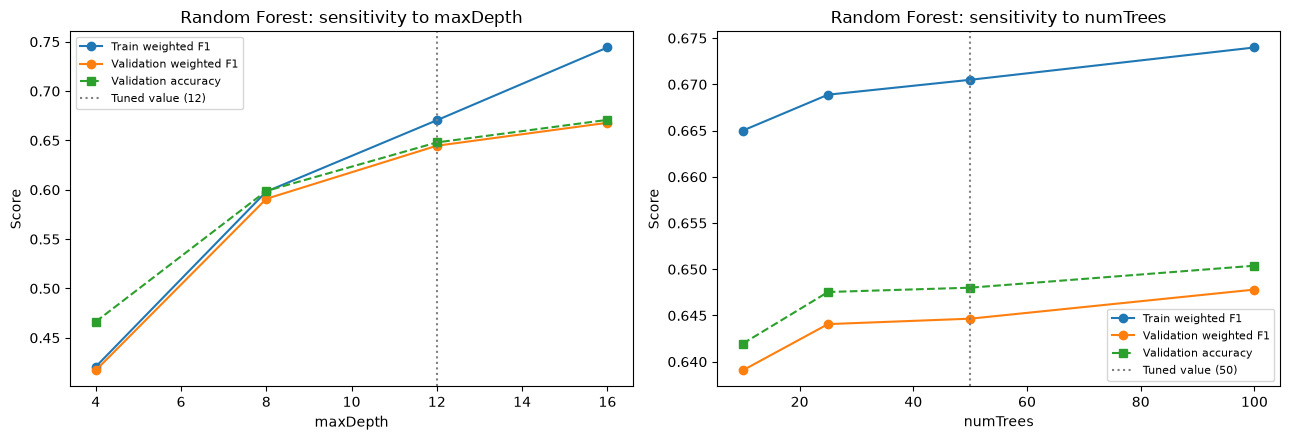

In [24]:
params = sensitivity["hyperparameter"].unique()
fig, axes = plt.subplots(1, len(params), figsize=(6.5 * len(params), 4.5), squeeze=False)
for ax, p in zip(axes[0], params):
    s = sensitivity[sensitivity["hyperparameter"] == p]
    ax.plot(s["value"], s["train_f1"], marker="o", label="Train weighted F1")
    ax.plot(s["value"], s["valid_f1"], marker="o", label="Validation weighted F1")
    ax.plot(s["value"], s["valid_accuracy"], marker="s", ls="--", label="Validation accuracy")
    tuned_p = [v for k, v in tuned.items() if k.name == p][0]
    ax.axvline(tuned_p, color="gray", ls=":", label=f"Tuned value ({tuned_p})")
    ax.set_xlabel(p)
    ax.set_ylabel("Score")
    ax.set_title(f"{CHAMPION}: sensitivity to {p}")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

**Reading the sensitivity plots:** a widening gap between train and validation F1 as a hyperparameter grows
indicates overfitting; a flat validation curve means the model is not very sensitive to that setting and a
cheaper value could be used with little loss.

## 7. Summary

The cell below prints the key numbers for the paper and presentation.

In [25]:
champ = comparison.set_index("model").loc[CHAMPION]
bench = comparison.set_index("model").loc["Benchmark LR"]
print(f"Champion model: {CHAMPION}")
print(f"  Test accuracy:      {champ['Test accuracy']:.4f}   (benchmark {bench['Test accuracy']:.4f}, "
      f"majority class {MAJORITY_SHARE:.4f})")
print(f"  Test weighted F1:   {champ['Test weighted F1']:.4f}   (benchmark {bench['Test weighted F1']:.4f})")
print(f"  Test macro AUROC:   {champ['Test macro AUROC']:.4f}   (benchmark {bench['Test macro AUROC']:.4f})")
pc = per_class_tables[CHAMPION].set_index("borough")
print(f"  Easiest borough to identify (F1): {pc['f1'].idxmax()} ({pc['f1'].max():.3f})")
print(f"  Hardest borough to identify (F1): {pc['f1'].idxmin()} ({pc['f1'].min():.3f})")
print(f"  Top 3 features: {', '.join(imp.sort_values(CHAMPION if CHAMPION in imp else 'Random Forest', ascending=False).index[:3])}")

Champion model: Random Forest
  Test accuracy:      0.6468   (benchmark 0.4364, majority class 0.3054)
  Test weighted F1:   0.6443   (benchmark 0.4063)
  Test macro AUROC:   0.8969   (benchmark 0.7639)
  Easiest borough to identify (F1): Manhattan (0.842)
  Hardest borough to identify (F1): Bronx (0.422)
  Top 3 features: building_age, log_sale_price, log_land_sqft


**Interpretation notes for the write-up**

- Compare the champion's accuracy to the majority-class baseline: any gain above it is information the
  property characteristics carry about location, since all location columns were removed.
- The confusion matrices show which boroughs are confused. Boroughs with similar housing stock and price levels
  are expected to be confused with each other, while boroughs with distinctive building types or prices should be
  easier to identify.
- Class weights trade a little overall accuracy for better recall on the smaller boroughs (Bronx, Staten Island).